# 08. 여러 시즌 시험 — 한 시즌으로 모자란 증거를 아홉 시즌으로 모으기

안녕하세요! **KBO 승패 예측 프로젝트의 여덟 번째 이야기**예요. 짝이 되는 코드는 `src/kbo_predict/backtest.py`예요.

**이 노트북이 하는 일**
- 2018~2026 **아홉 시즌**마다 "그 앞 시즌들로만 학습 → 그 시즌 예측"을 되풀이해서, 미래를 보지 않은 예측 **6,328경기**를 모아요. 이런 방법을 **walk-forward 백테스트**(앞으로 걸어가며 하는 시험)라고 해요.
- 그 6,328경기로 승패 모델 후보 네 개(v0.2 설정, L1, **L1 + Elo**, 앙상블)를 비교하고, **계산 전에 정해 둔 규칙**으로 하나를 골라요. 여기서 뽑힌 **L1 + Elo**가 지금 모델 **v0.3**이에요.
- 결과는 `python -m kbo_predict.backtest`로 미리 만들어 둔 `data/public/backtest_report.json`에 있어요. 이 노트북은 **같은 계산을 여기서 다시 돌려** 결과 파일과 숫자가 같은지 확인해요(10초 남짓 걸려요).
- 시즌별·합친 성적을 표와 그림으로 보고, "우연이 아닐까?"를 검정 두 가지로 쉽게 따져 봐요. 정직하게 적어 둘 점도 함께 적어요.

**왜 필요한가요?**
- 03번의 성적표는 2026 **한 시즌(702경기)**으로 매겨요. 예전 v0.2는 가장 좋은 단순 규칙("선발 평균자책점 낮은 팀")보다 **+2.7%p** 높았지만 McNemar **p = 0.215**였어요. 702경기로는 이 정도 차이가 실력인지 운인지 가릴 수 없었던 거예요.
- 06·07번에서 튜닝한 후보(L1, C = 0.03)도 2026에서 v0.2보다 조금 좋았지만 p = 0.16이었어요. "정말 더 좋은가?"에 답하려면 **경기 수를 늘려야** 해요.
- 경기 수를 늘리는 정직한 방법은 "미래를 보지 않은 예측"을 여러 시즌에 걸쳐 모으는 거예요. 각 시즌의 예측은 **그 시즌보다 앞선 기록으로만** 학습한 모델이 내니까, 시험 누출이 없어요.

**읽는 순서**
1. 준비
2. 시즌마다 학습 → 예측 (walk-forward)
3. 후보와 고르는 규칙 — 계산 전에 정했어요
4. 다시 계산해서 결과 파일과 같은지 확인
5. 고르는 규칙 적용 — 개발 시즌 log loss
6. 합친 성적 — 전체 · 깨끗한 시즌 · 2026
7. 시즌별로 보기
8. 우연일까? — 검정 두 가지
9. 정직하게 적어 둘 점
10. 결론

> 결과만 궁금하시면 **6번(합친 성적)**과 **10번(결론)**만 보셔도 충분해요.
> 02번 노트북을 먼저 실행해서 `data/processed/features.parquet`(Elo 열 `elo_diff` 포함)가 있어야 해요. 인터넷 없이 30초 안팎이면 끝나요.

## 1. 준비

- 이 노트북은 `notebooks/` 폴더에서 실행되니까, 한 단계 위가 프로젝트 루트예요. `src/`를 파이썬 경로에 넣어 `kbo_predict`를 불러와요.
- 랜덤포레스트가 CPU 코어 수를 찾다가 내는 안내 메시지를 막으려고 `LOKY_MAX_CPU_COUNT`를 먼저 정해요(결과에는 영향이 없어요).
- 02번 노트북이 만든 피처 표와 여러 시즌 시험 결과 파일(`backtest_report.json`)을 읽어요.

**출력 보는 법:** 경기 수와 시즌 범위, `elo_diff` 열이 있는지, 결과 파일을 만든 시각과 고른 후보가 나오면 준비 끝이에요.

In [1]:
import json
import logging
import os
import sys
import time
import warnings
from pathlib import Path

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")          # scikit-learn이 코어 수를 찾다 내는 경고를 막아요
warnings.filterwarnings("ignore")                          # 라이브러리 버전·수렴 안내 메시지는 숨겨요 (계산에는 영향 없음)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import PercentFormatter

T0 = time.time()                                           # 노트북 전체 실행 시간을 재기 시작
ROOT = Path.cwd().parent                                   # notebooks/의 한 단계 위 = 프로젝트 루트
sys.path.insert(0, str(ROOT / "src"))                      # kbo_predict 패키지를 불러오기 위해

from kbo_predict import backtest                           # 여러 시즌 시험 (이 노트북의 짝)
from kbo_predict import train_win as tw                    # McNemar 검정 (03번과 같은 함수)
from kbo_predict.features import FEATURE_NAMES, load_features

# 그래프 한글 폰트와 모양 (03번과 같아요)
plt.rcParams["font.family"] = ["Malgun Gothic", "AppleGothic", "NanumGothic", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)  # 없는 후보 폰트 안내 메시지는 숨겨요
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e5e4e0", "axes.axisbelow": True})
BLUE, ORANGE, GRAY, INK = "#2a78d6", "#e07b39", "#b8b6b0", "#52514e"  # 고른 후보, 단순 규칙, 나머지 후보, 글자·보조선
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 80)

df = load_features(ROOT / "data" / "processed" / "features.parquet")
report = json.loads((ROOT / "data" / "public" / "backtest_report.json").read_text(encoding="utf-8"))
NAMES = list(backtest.CANDIDATES)                           # 후보 네 개: current, l1, l1_elo, ensemble
KO = {n: report["candidates"][n]["label"] for n in NAMES}  # 후보의 한글 이름
CHOSEN = report["chosen"]                                   # 규칙으로 고른 후보
RULE_KO = report["rules"]                                   # 단순 규칙 세 개의 한글 이름

print(f"피처 표 {len(df):,}경기 · 시즌 {df['season'].min()}~{df['season'].max()} · elo_diff 열 있나요?: {'elo_diff' in df.columns}")
print(f"결과 파일 만든 시각 {report['generated_at']} · 계산에 걸린 시간 {report['elapsed_sec']}초 · 고른 후보: {CHOSEN} ({KO[CHOSEN]})")

피처 표 8,465경기 · 시즌 2015~2026 · elo_diff 열 있나요?: True
결과 파일 만든 시각 2026-11-03T10:32:11+09:00 · 계산에 걸린 시간 11.5초 · 고른 후보: l1_elo (로지스틱 L1 + Elo)


## 2. 시즌마다 학습 → 예측 (walk-forward)

방법은 아주 단순해요. **시즌 하나를 예측할 때마다, 그보다 앞선 시즌만으로 새로 학습**해요.
- 2018을 예측할 때는 2015~2017로 학습하고,
- 2019를 예측할 때는 2015~2018로 학습하고, …
- 2026을 예측할 때는 2015~2025로 학습해요.

그러면 아홉 시즌의 모든 경기가 "그 경기를 전혀 모르는 모델의 예측"을 하나씩 갖게 돼요. 실제로 해마다 모델을 다시 학습해 다음 시즌을 예측하는 것과 같은 모양이에요.
2015~2017은 학습만 해요(학습할 시즌이 최소 3개는 있어야 해서요).

시즌은 쓰임에 따라 나눠요.
- **개발 시즌(2018~2025):** 후보를 **고르는** 데 써요.
- **시험 시즌(2026):** 고른 뒤 **채점만** 해요.
- **깨끗한 시즌(2018~2020, 2026):** 어떤 설정 선택에도 쓰지 않은 시즌이에요. 06·07번의 튜닝이 2021~2025 교차검증을 썼기 때문에, 그 시즌을 뺀 성적도 따로 봐요(9번에서 자세히).

**출력 보는 법:** 한 줄이 예측하는 시즌 하나예요. 학습 경기 수는 시즌이 갈수록 늘어나요.

In [2]:
proto = report["protocol"]
folds = pd.DataFrame([{
    "예측하는 시즌": s,
    "학습 시즌": f"{df['season'].min()}~{s - 1}",
    "학습 경기 수": int((df["season"] < s).sum()),           # 그 시즌보다 앞선 경기만
    "예측 경기 수": report["by_season"][str(s)]["n"],
    "쓰임": "시험 (고른 뒤 채점만)" if s == proto["test_season"] else "개발 (후보 고르기)",
    "깨끗한 시즌?": "예" if s in proto["clean_seasons"] else "아니요 (06·07 교차검증에 씀)",
} for s in proto["seasons"]]).set_index("예측하는 시즌")
display(folds)
print(f"예측한 경기 합계 {folds['예측 경기 수'].sum():,}경기 = 개발 {report['pooled']['dev']['n']:,} + 시험 {report['pooled']['test']['n']:,}"
      f" · 깨끗한 시즌 {report['pooled']['clean']['n']:,}경기")

,학습 시즌,학습 경기 수,예측 경기 수,쓰임,깨끗한 시즌?
예측하는 시즌,,,,,
2018,2015~2017,2137,714,개발 (후보 고르기),예
2019,2015~2018,2851,713,개발 (후보 고르기),예
2020,2015~2019,3564,707,개발 (후보 고르기),예
2021,2015~2020,4271,670,개발 (후보 고르기),아니요 (06·07 교차검증에 씀)
2022,2015~2021,4941,707,개발 (후보 고르기),아니요 (06·07 교차검증에 씀)
2023,2015~2022,5648,707,개발 (후보 고르기),아니요 (06·07 교차검증에 씀)
2024,2015~2023,6355,710,개발 (후보 고르기),아니요 (06·07 교차검증에 씀)
2025,2015~2024,7065,698,개발 (후보 고르기),아니요 (06·07 교차검증에 씀)
2026,2015~2025,7763,702,시험 (고른 뒤 채점만),예


예측한 경기 합계 6,328경기 = 개발 5,626 + 시험 702 · 깨끗한 시즌 2,836경기


**해석:** 2018 예측은 2,137경기로 배우고, 2026 예측은 7,763경기로 배워요. 아홉 시즌을 합치면 **6,328경기**예요. 03번 성적표(702경기)의 9배쯤 되니, 작은 차이도 훨씬 또렷하게 볼 수 있어요.

## 3. 후보와 고르는 규칙 — 계산 전에 정했어요

여러 후보를 시험해 보고 "제일 좋은 것"을 고르면, 그것도 운 좋은 후보를 고를 위험이 있어요. 그래서 **후보 목록과 고르는 규칙을 계산하기 전에 적어 두었어요**(`backtest.py` 맨 위 설명, 2026-11-03).

| 후보 | 무엇인가요 |
|---|---|
| `current` | **v0.2 설정** — 예전 라이브 모델과 같은 로지스틱 회귀(L2, C = 1), 피처 26개 |
| `l1` | 로지스틱 회귀 **L1, C = 0.03** — 06번 랜덤 서치의 추천이자 07번 오토머신러닝이 따로 고른 값 |
| `l1_elo` | `l1` + **Elo 전력 점수 차이** 피처 1개(02번 4-1) — Elo 설정은 미리 고정, 튜닝하지 않음 |
| `ensemble` | `l1` + 07번 그리드 1등 랜덤포레스트 + 그리드 1등 XGBoost의 **확률 평균** |

- **고르는 규칙:** 개발 시즌 2018~2025를 합친 **log loss가 가장 낮은** 후보. log loss는 "확률을 얼마나 잘 말했나"를 보는 점수라 정확도보다 민감해요(03번 4장).
- **확률 보정(Platt 등)은 하지 않아요.** 시즌마다 보정용 시즌을 따로 떼면 학습 기록이 줄어 비교가 흔들리거든요. 모든 후보가 같은 조건(보정 없음)이라 공정해요.

**출력 보는 법:** 결과 파일에 적힌 후보 설정과 규칙을 그대로 꺼내 보여 줘요.

In [3]:
cand_tbl = pd.DataFrame([{
    "후보": n, "이름": KO[n],
    "모델(계열: 설정)": " + ".join(f"{fam}: {params}" if fam == "logreg" else fam for fam, params in report["candidates"][n]["members"]),
    "피처 수": len(FEATURE_NAMES) + int(report["candidates"][n]["elo"]),   # 26개 (+ Elo 1개)
} for n in NAMES]).set_index("후보")
display(cand_tbl)
elo = proto["elo"]
print("고르는 규칙:", proto["selection_rule"])
print("확률 보정  :", proto["calibration"])
print(f"Elo 설정   : K = {elo['k']:g}, 홈 이점 +{elo['home']:g}점, 새 시즌에 평균 쪽으로 {1 - elo['carry']:.0%} 되돌림, 처음 {elo['base']:g}점 — 튜닝했나요?: {elo['tuned']}")

,이름,모델(계열: 설정),피처 수
후보,,,
current,"v0.2 설정 (로지스틱 L2, C=1)","logreg: {'C': 1.0, 'penalty': 'l2'}",26
l1,"로지스틱 L1, C=0.03","logreg: {'C': 0.03, 'penalty': 'l1'}",26
l1_elo,로지스틱 L1 + Elo,"logreg: {'C': 0.03, 'penalty': 'l1'}",27
ensemble,앙상블 (L1 + 랜덤포레스트 + XGBoost 평균),"logreg: {'C': 0.03, 'penalty': 'l1'} + random_forest + xgboost",26


고르는 규칙: lowest pooled log loss over dev seasons (decided 2026-11-03 before computing)
확률 보정  : none (all candidates)
Elo 설정   : K = 6, 홈 이점 +20점, 새 시즌에 평균 쪽으로 33% 되돌림, 처음 1500점 — 튜닝했나요?: False


## 4. 다시 계산해서 결과 파일과 같은지 확인

`backtest.run(df)`가 명령줄(`python -m kbo_predict.backtest`)과 똑같은 계산을 해요. 아홉 시즌마다 후보 네 개를 학습하고 예측한 뒤, 시즌별·합친 범위별 정확도·log loss·검정 p값을 모아요.
여기서 다시 계산한 숫자를 결과 파일의 숫자와 **하나씩** 비교해요. 랜덤포레스트는 나무 여러 개를 병렬로 더하는 순서 때문에 소수점 16번째 자리쯤이 달라질 수 있어서(07번과 같은 이유), **10억분의 1(1e-9) 이내면 같다**고 봐요.

**출력 보는 법:** 위의 아홉 줄은 시즌마다의 학습 → 예측 기록이에요. 마지막 줄이 "같아요"면 결과 파일 = 이 노트북의 계산이에요.

In [4]:
rerun = backtest.run(df)                                    # 시즌마다 학습 → 예측 (아홉 번), 그리고 요약
rerun = json.loads(json.dumps(rerun, ensure_ascii=False, default=str))   # 결과 파일과 같은 모양으로 (시즌 키가 문자열이 돼요)

METRICS = [(n, m) for n in NAMES for m in ("accuracy", "log_loss")] + [(f"rule_{r}", "accuracy") for r in backtest.RULES]
pairs = []                                                  # (어디, 결과 파일 값, 다시 계산한 값)
for part in ("pooled", "by_season"):                        # 합친 범위 4개(dev·all·clean·test) + 시즌 9개
    for key, saved in report[part].items():
        new = rerun[part][key]
        pairs.append((f"{part}.{key}.n", saved["n"], new["n"]))
        pairs += [(f"{part}.{key}.{n}.{m}", saved[n][m], new[n][m]) for n, m in METRICS]
        pairs += [(f"{part}.{key}.tests.{n}.{t}", v, new["tests"][n][t]) for n in NAMES for t, v in saved["tests"][n].items()]
diffs = [(where, a, b) for where, a, b in pairs if not np.isclose(a, b, rtol=0, atol=1e-9)]
same = not diffs and rerun["chosen"] == report["chosen"]
print(f"비교한 숫자 {len(pairs)}개 · 다시 계산해도 고른 후보: {rerun['chosen']}")
print("노트북에서 다시 계산한 숫자가 결과 파일과 같나요? (차이 1e-9 이내)", "같아요" if same else f"달라요 — 처음 다른 곳 {diffs[:3]}")

[backtest] 2018: 학습 2015~2017 2,137경기 → 예측 714경기


[backtest] 2019: 학습 2015~2018 2,851경기 → 예측 713경기


[backtest] 2020: 학습 2015~2019 3,564경기 → 예측 707경기


[backtest] 2021: 학습 2015~2020 4,271경기 → 예측 670경기


[backtest] 2022: 학습 2015~2021 4,941경기 → 예측 707경기


[backtest] 2023: 학습 2015~2022 5,648경기 → 예측 707경기


[backtest] 2024: 학습 2015~2023 6,355경기 → 예측 710경기


[backtest] 2025: 학습 2015~2024 7,065경기 → 예측 698경기


[backtest] 2026: 학습 2015~2025 7,763경기 → 예측 702경기


비교한 숫자 429개 · 다시 계산해도 고른 후보: l1_elo
노트북에서 다시 계산한 숫자가 결과 파일과 같나요? (차이 1e-9 이내) 같아요


## 5. 고르는 규칙 적용 — 개발 시즌 log loss

이제 3번에서 정한 규칙대로 골라요. 개발 시즌(2018~2025, 5,626경기)을 합친 **log loss가 가장 낮은 후보**예요.
`v0.2 설정보다 줄어든 log loss`는 경기당 평균으로 v0.2 설정보다 얼마나 나아졌는지예요(클수록 좋아요).

**출력 보는 법:** log loss가 낮은 순서로 정렬했어요. `✔`가 규칙으로 고른 후보예요. 정확도는 참고로 함께 적어요.

In [5]:
dev = report["pooled"]["dev"]
sel = pd.DataFrame([{
    "후보": KO[n], "개발 log loss": dev[n]["log_loss"], "개발 정확도": dev[n]["accuracy"],
    "v0.2 설정보다 줄어든 log loss": dev["tests"][n].get("logloss_gain_vs_current", np.nan),
    "고른 후보": "✔" if n == CHOSEN else "",
} for n in NAMES]).sort_values("개발 log loss")
display(sel.style.format({"개발 log loss": "{:.5f}", "개발 정확도": "{:.1%}",
                          "v0.2 설정보다 줄어든 log loss": lambda v: "—" if pd.isna(v) else f"{v:.4f}"}).hide(axis="index"))
print(f"규칙(개발 시즌 {dev['seasons'][0]}~{dev['seasons'][-1]}, {dev['n']:,}경기의 log loss 최저) → {KO[CHOSEN]}")

후보,개발 log loss,개발 정확도,v0.2 설정보다 줄어든 log loss,고른 후보
로지스틱 L1 + Elo,0.67821,57.6%,0.0056,✔
앙상블 (L1 + 랜덤포레스트 + XGBoost 평균),0.67871,57.3%,0.0051,
"로지스틱 L1, C=0.03",0.67937,57.1%,0.0044,
"v0.2 설정 (로지스틱 L2, C=1)",0.68380,56.0%,—,


규칙(개발 시즌 2018~2025, 5,626경기의 log loss 최저) → 로지스틱 L1 + Elo


**해석:**
- **L1 + Elo**가 log loss 0.67821로 가장 낮아서 뽑혔어요. 앙상블(0.67871), L1(0.67937)이 뒤를 잇고, v0.2 설정(0.68380)이 가장 높아요(나빠요).
- 경기당 0.0056은 작아 보이지만, 03번에서 봤듯 모든 모델이 0.67~0.69의 좁은 폭에 있어요. 그 폭의 4분의 1쯤 되는 차이예요.
- 정확도도 같은 순서예요(L1 + Elo 57.6% → v0.2 설정 56.0%). 고르는 기준(log loss)과 보기 쉬운 지표(정확도)가 같은 답을 줬어요.
- 복잡한 앙상블(나무 모델 두 개를 섞은 것)이 단순한 L1 + Elo를 넘지 못했어요. 06·07번에서 본 "이 데이터에서는 단순한 로지스틱 회귀가 강하다"는 결론과 같아요.

## 6. 합친 성적 — 전체 · 깨끗한 시즌 · 2026

고른 뒤에는 세 가지 범위로 채점해요.
- **2018~2026 전체**(6,328경기): 가장 많은 경기.
- **깨끗한 시즌**(2018~2020, 2026 — 2,836경기): 어떤 설정 선택에도 쓰지 않은 시즌. 가장 공정한 범위예요.
- **2026 시험**(702경기): 고르는 데 전혀 쓰지 않은 시즌.

단순 규칙 세 개(항상 홈팀 / 시즌 승률이 높은 팀 / 선발 평균자책점이 낮은 팀)도 같은 경기로 채점해요.

**출력 보는 법:** 표는 범위별 정확도예요. 그림은 전체와 깨끗한 시즌의 정확도 막대예요. 파랑 = 고른 후보(L1 + Elo), 회색 = 나머지 후보, 주황 = 단순 규칙이에요.

,경기 수,"v0.2 설정 (로지스틱 L2, C=1)","로지스틱 L1, C=0.03",로지스틱 L1 + Elo,앙상블 (L1 + 랜덤포레스트 + XGBoost 평균),규칙: 항상 홈팀,규칙: 시즌 승률이 높은 팀,규칙: 선발 평균자책점이 낮은 팀
범위,,,,,,,,
2018~2026 전체,6328,56.5%,57.4%,57.9%,57.6%,52.4%,55.3%,54.7%
"깨끗한 시즌 (2018~2020, 2026)",2836,56.8%,58.0%,58.9%,58.5%,53.4%,55.9%,55.1%
2026 시험,702,60.3%,59.8%,60.8%,60.3%,51.4%,55.4%,56.7%


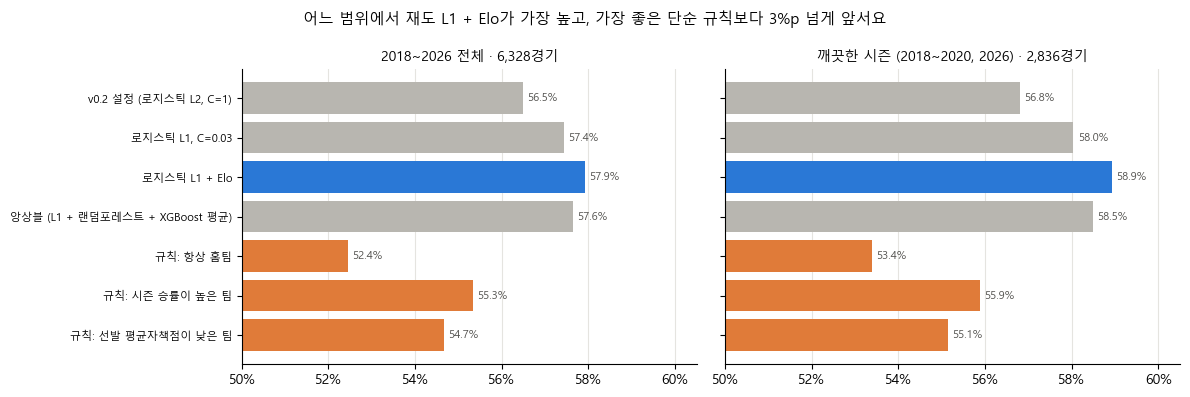

전체: L1 + Elo 57.9% vs 선발 평균자책점 규칙 54.7% (+3.3%p) · v0.2 설정 56.5%
깨끗한 시즌: L1 + Elo 58.9% vs 선발 평균자책점 규칙 55.1% (+3.8%p) · v0.2 설정 56.8%


In [6]:
SCOPE_KO = {"all": "2018~2026 전체", "clean": "깨끗한 시즌 (2018~2020, 2026)", "test": "2026 시험"}
acc = pd.DataFrame([{"범위": SCOPE_KO[sc], "경기 수": report["pooled"][sc]["n"],
                     **{KO[n]: report["pooled"][sc][n]["accuracy"] for n in NAMES},
                     **{f"규칙: {RULE_KO[r]}": report["pooled"][sc][f"rule_{r}"]["accuracy"] for r in backtest.RULES}}
                    for sc in SCOPE_KO]).set_index("범위")
display(acc.style.format({c: "{:.1%}" for c in acc.columns if c != "경기 수"}))

items = [(KO[n], n) for n in NAMES] + [(f"규칙: {RULE_KO[r]}", f"rule_{r}") for r in backtest.RULES]
colors = [BLUE if key == CHOSEN else ORANGE if key.startswith("rule_") else GRAY for _, key in items]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, sc in zip(axes, ("all", "clean")):
    vals = [report["pooled"][sc][key]["accuracy"] for _, key in items]
    bars = ax.barh([label for label, _ in items][::-1], vals[::-1], color=colors[::-1])
    ax.bar_label(bars, labels=[f"{v:.1%}" for v in vals[::-1]], fontsize=8, color=INK, padding=3)
    ax.set_xlim(0.50, 0.605)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.grid(True, axis="x"); ax.grid(False, axis="y")
    ax.set_title(f"{SCOPE_KO[sc]} · {report['pooled'][sc]['n']:,}경기", fontsize=10)
axes[0].tick_params(axis="y", labelsize=8)
fig.suptitle("어느 범위에서 재도 L1 + Elo가 가장 높고, 가장 좋은 단순 규칙보다 3%p 넘게 앞서요", fontsize=11)
fig.tight_layout()
plt.show()

a, c = report["pooled"]["all"], report["pooled"]["clean"]
print(f"전체: L1 + Elo {a[CHOSEN]['accuracy']:.1%} vs 선발 평균자책점 규칙 {a['rule_lower_starter_era']['accuracy']:.1%}"
      f" (+{100 * (a[CHOSEN]['accuracy'] - a['rule_lower_starter_era']['accuracy']):.1f}%p) · v0.2 설정 {a['current']['accuracy']:.1%}")
print(f"깨끗한 시즌: L1 + Elo {c[CHOSEN]['accuracy']:.1%} vs 선발 평균자책점 규칙 {c['rule_lower_starter_era']['accuracy']:.1%}"
      f" (+{100 * (c[CHOSEN]['accuracy'] - c['rule_lower_starter_era']['accuracy']):.1f}%p) · v0.2 설정 {c['current']['accuracy']:.1%}")

**해석:**
- **2018~2026 전체:** L1 + Elo가 **57.9%**로 가장 높아요. 가장 좋은 단순 규칙인 "선발 평균자책점 낮은 팀"(54.7%)보다 **+3.3%p**, v0.2 설정(56.5%)보다 +1.4%p예요.
- **깨끗한 시즌(2018~2020, 2026):** L1 + Elo **58.9%** vs 규칙 55.1%로 **+3.8%p**예요. 설정 선택에 쓰지 않은 시즌만 모아도 차이가 줄지 않았어요. 오히려 조금 커졌어요.
- **2026 시험:** L1 + Elo 60.8%로 네 후보 중 가장 높아요. 규칙(56.7%)보다 +4.1%p예요.
- 참고로 이 표에서는 "시즌 승률이 높은 팀"(55.3%)이 "선발 평균자책점 낮은 팀"(54.7%)보다 조금 높아요. 03번은 2025에서 가장 잘한 규칙(선발 평균자책점)을 비교 대상으로 미리 정했고, 이 노트북도 그 약속을 따라 선발 평균자책점 규칙을 주 비교 대상으로 써요. 두 규칙 모두와의 검정 결과는 결과 파일에 함께 있어요.

## 7. 시즌별로 보기

합친 성적이 좋아도 한두 시즌이 끌어올린 것일 수 있어요. 시즌마다 따로 보면 **꾸준한지** 알 수 있어요.

**출력 보는 법:** 파란 굵은 선 = L1 + Elo, 회색 선 = 나머지 후보 세 개(v0.2 설정은 점선), 주황 점선 = 선발 평균자책점 규칙이에요. 아래 표의 `차이(%p)`는 L1 + Elo − 규칙, `p`는 그 시즌 702경기 안팎으로만 한 McNemar 검정이에요.

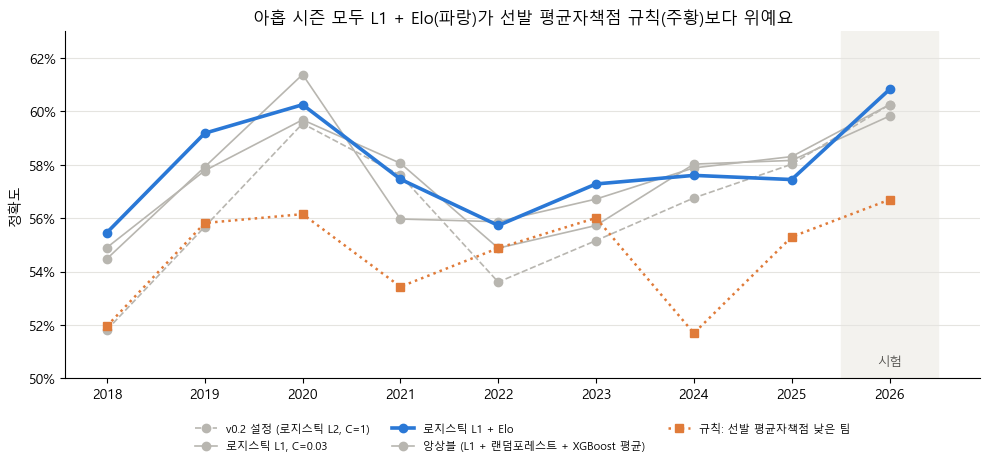

,"v0.2 설정 (로지스틱 L2, C=1)","로지스틱 L1, C=0.03",로지스틱 L1 + Elo,앙상블 (L1 + 랜덤포레스트 + XGBoost 평균),규칙: 선발 평균자책점,차이(%p),p (vs 규칙)
2018,51.8%,54.9%,55.5%,54.5%,52.0%,+3.5,0.095
2019,55.7%,57.8%,59.2%,57.9%,55.8%,+3.4,0.112
2020,59.5%,59.7%,60.3%,61.4%,56.2%,+4.1,0.049
2021,57.6%,58.1%,57.5%,56.0%,53.4%,+4.0,0.066
2022,53.6%,54.9%,55.7%,55.9%,54.9%,+0.8,0.750
2023,55.2%,55.7%,57.3%,56.7%,56.0%,+1.3,0.591
2024,56.8%,58.0%,57.6%,57.9%,51.7%,+5.9,0.006
2025,58.0%,58.2%,57.4%,58.3%,55.3%,+2.1,0.333
2026,60.3%,59.8%,60.8%,60.3%,56.7%,+4.1,0.044


L1 + Elo가 규칙보다 높은 시즌 9개 / 9개 · 그 시즌 혼자서 p < 0.05인 시즌 3개 · v0.2 설정보다 높은 시즌 7개


In [7]:
seasons = proto["seasons"]
per = pd.DataFrame({KO[n]: [report["by_season"][str(s)][n]["accuracy"] for s in seasons] for n in NAMES}, index=seasons)
per["규칙: 선발 평균자책점"] = [report["by_season"][str(s)]["rule_lower_starter_era"]["accuracy"] for s in seasons]

fig, ax = plt.subplots(figsize=(10, 4.8))
for n in NAMES:
    ax.plot(seasons, per[KO[n]], marker="o", color=BLUE if n == CHOSEN else GRAY,
            linewidth=2.6 if n == CHOSEN else 1.2, linestyle="--" if n == "current" else "-", label=KO[n], zorder=3 if n == CHOSEN else 2)
ax.plot(seasons, per["규칙: 선발 평균자책점"], marker="s", color=ORANGE, linestyle=":", linewidth=1.8, label="규칙: 선발 평균자책점 낮은 팀")
ax.axvspan(2025.5, 2026.5, color="#f3f2ee", zorder=0)
ax.text(2026, 0.505, "시험", ha="center", fontsize=9, color=INK)
ax.set_xticks(seasons)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set(ylim=(0.50, 0.63), ylabel="정확도", title="아홉 시즌 모두 L1 + Elo(파랑)가 선발 평균자책점 규칙(주황)보다 위예요")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)   # 범례는 그림 아래에
plt.tight_layout()
plt.show()

per_tbl = per.copy()
per_tbl["차이(%p)"] = 100 * (per[KO[CHOSEN]] - per["규칙: 선발 평균자책점"])
per_tbl["p (vs 규칙)"] = [report["by_season"][str(s)]["tests"][CHOSEN]["mcnemar_p_vs_rule_lower_starter_era"] for s in seasons]
display(per_tbl.style.format({**{c: "{:.1%}" for c in per.columns}, "차이(%p)": "{:+.1f}", "p (vs 규칙)": "{:.3f}"}))
print(f"L1 + Elo가 규칙보다 높은 시즌 {int((per_tbl['차이(%p)'] > 0).sum())}개 / {len(seasons)}개 · 그 시즌 혼자서 p < 0.05인 시즌 {int((per_tbl['p (vs 규칙)'] < 0.05).sum())}개"
      f" · v0.2 설정보다 높은 시즌 {int((per[KO[CHOSEN]] > per[KO['current']]).sum())}개")

**해석:**
- **아홉 시즌 모두** L1 + Elo가 선발 평균자책점 규칙보다 높아요(2022의 +0.8%p ~ 2024의 +5.9%p).
- 그런데 시즌 하나만 놓고 p < 0.05인 시즌은 **세 개뿐**이에요(2020, 2024, 2026). 나머지 여섯 시즌은 혼자서는 "우연일 수도"예요. 이게 바로 한 시즌(약 700경기)으로는 증거가 모자란 이유예요.
- 하나하나는 약해도 **같은 방향이 아홉 번 되풀이**되면 이야기가 달라져요. 동전 하나가 앞면이 6:4로 나온 건 별일 아니지만, 아홉 번 연속 앞면이 더 많이 나오면 그 동전을 의심하게 되죠. 경기를 합쳐서 검정하는 게 8번이에요.
- v0.2 설정과 비교하면 L1 + Elo가 일곱 시즌에서 높고, 2021·2025 두 시즌은 조금 낮아요(−0.1%p, −0.6%p). 시즌별로는 흔들려도 합치면 앞서요.

## 8. 우연일까? — 검정 두 가지

### McNemar 검정 (정확도) — "한쪽만 맞힌 경기"로 보기
두 방법이 **같은 경기들**을 함께 풀었을 때, 둘 다 맞히거나 둘 다 틀린 경기는 차이를 말해 주지 않아요. 그래서 **한쪽만 맞힌 경기**만 봐요.
실력이 같다면 한쪽만 맞힌 경기는 동전 던지기처럼 반반으로 나뉘어야 해요. 실제로 얼마나 한쪽으로 쏠렸는지로 p값을 계산해요(`tw.mcnemar_p`, 03번과 같은 함수).

### 대응표본 t 검정 (log loss) — "경기마다 확률 점수가 나아졌나"
log loss는 경기마다 점수가 하나씩 있어요. 같은 경기에서 "v0.2 설정의 점수 − L1 + Elo의 점수"를 경기마다 구하고, 그 **평균이 0과 다른지** 봐요(`backtest.paired_t_p`).
정확도는 "맞았다/틀렸다"만 보지만, log loss는 **확률을 얼마나 잘 말했는지**까지 봐서 더 민감해요.

**p값**은 "실력이 같은데도 우연히 이만큼(이상) 차이 날 확률"이에요. 보통 0.05보다 작으면 "우연으로 보기 어렵다 = 유의하다"고 해요.

검정 재료를 직접 보려고, 시즌마다의 경기별 예측을 한 번 더 만들어요(`backtest.predictions` — 4번의 `run`이 안에서 쓰는 바로 그 함수예요). 그걸로 b·c를 세고, p값이 결과 파일과 같은지도 확인해요.

**출력 보는 법:** `L1 + Elo만 맞힘(b)`과 `상대만 맞힘(c)`만 검정에 들어가요. `차이(%p)` = (b − c) ÷ 경기 수예요. 아래 줄은 log loss 검정이에요.

In [8]:
pred = backtest.predictions(df, log=lambda *_: None)         # 시즌마다 경기별 P(홈 승) (4번과 같은 계산, 기록 출력은 생략)
y = pred["y"].to_numpy()
ok = {n: (pred[n].to_numpy() >= 0.5).astype(int) == y for n in NAMES}   # 확률 ≥ 50%면 홈 승으로 찍어요 (03번과 같은 규칙)
ok_rule = pred["rule_lower_starter_era"].to_numpy() == y                 # 선발 평균자책점 규칙이 맞혔나

rows = []
for sc in SCOPE_KO:
    m = pred["season"].isin(report["pooled"][sc]["seasons"]).to_numpy()  # 이 범위의 경기만
    for label, other, key in (("규칙: 선발 평균자책점", ok_rule, "mcnemar_p_vs_rule_lower_starter_era"),
                              (KO["current"], ok["current"], "mcnemar_p_vs_current")):
        b, c = int((ok[CHOSEN] & ~other & m).sum()), int((~ok[CHOSEN] & other & m).sum())
        p = tw.mcnemar_p(ok[CHOSEN][m], other[m])
        rows.append({"범위": SCOPE_KO[sc], "비교 상대": label, "경기 수": int(m.sum()), "L1 + Elo만 맞힘(b)": b, "상대만 맞힘(c)": c,
                     "차이(%p)": 100 * (b - c) / m.sum(), "McNemar p": p,
                     "결과 파일과 같나요?": bool(np.isclose(p, report["pooled"][sc]["tests"][CHOSEN][key], rtol=0, atol=1e-9))})
tests = pd.DataFrame(rows).set_index(["범위", "비교 상대"])
display(tests.style.format({"차이(%p)": "{:+.1f}", "McNemar p": lambda v: "< 0.0001" if v < 1e-4 else f"{v:.4f}"}))

# log loss 대응표본 검정: 경기마다 log loss를 구해 비교해요 (backtest와 같은 자르기 EPS)
p_ch, p_cur = np.clip(pred[CHOSEN].to_numpy(), backtest.EPS, 1 - backtest.EPS), np.clip(pred["current"].to_numpy(), backtest.EPS, 1 - backtest.EPS)
ll_ch = -(y * np.log(p_ch) + (1 - y) * np.log(1 - p_ch))
ll_cur = -(y * np.log(p_cur) + (1 - y) * np.log(1 - p_cur))
p_ll = backtest.paired_t_p(ll_ch, ll_cur)
print(f"log loss (2018~2026 전체): v0.2 설정 {ll_cur.mean():.5f} → L1 + Elo {ll_ch.mean():.5f} (경기당 {ll_cur.mean() - ll_ch.mean():.4f} 줄어듦)"
      f" · 대응표본 검정 p = {p_ll:.6f}"
      f" (결과 파일과 같나요?: {bool(np.isclose(p_ll, report['pooled']['all']['tests'][CHOSEN]['logloss_p_vs_current'], rtol=0, atol=1e-9))})")

log loss (2018~2026 전체): v0.2 설정 0.68227 → L1 + Elo 0.67694 (경기당 0.0053 줄어듦) · 대응표본 검정 p = 0.000013 (결과 파일과 같나요?: True)


**해석:**
- **2018~2026 전체, 규칙과 비교:** 6,328경기 중 승부가 갈린 경기는 1,918개이고, 그중 L1 + Elo가 **1,062개(b)**, 규칙이 **856개(c)**를 가져갔어요. 차이 +3.3%p의 p값은 **0.0001보다 작아요.** 실력이 같다면 1,918번 동전을 던져 이만큼 쏠리기는 거의 불가능해요.
- **깨끗한 시즌만 봐도** 규칙과의 차이(460 대 353, +3.8%p)가 p = 0.0002로 유의해요. 설정 선택에 쓴 시즌을 빼도 결론이 그대로예요.
- **v0.2 설정과 비교:** 전체에서 415 대 324, +1.4%p, McNemar p = 0.0009예요. log loss로 보면 경기당 0.0053 줄었고(0.68227 → 0.67694) 대응표본 검정 p는 0.000013이에요. "L1 + Elo가 v0.2 설정보다 확률을 더 잘 말한다"는 것도 우연으로 보기 어려워요.
- **2026 한 시즌만** 보면 규칙과의 차이(111 대 82, +4.1%p)는 p = 0.044로 겨우 유의하고, v0.2 설정과의 차이(31 대 27, +0.6%p)는 p = 0.69로 전혀 구별되지 않아요. 한 시즌으로는 1%p 남짓한 차이를 가려낼 수 없다는 걸 다시 보여 줘요.

### 702경기로는 왜 모자랐을까?
아래는 "한쪽만 맞힌 경기 수가 이만큼일 때, p < 0.05가 되려면 정확도 차이가 몇 %p 필요한가"예요. 위 표의 2026·전체 범위의 b + c를 그대로 넣었어요.

**출력 보는 법:** 경기 수가 9배가 되면 필요한 차이는 약 3분의 1로 줄어요(제곱근 법칙).

In [9]:
need_rows = []
for sc in ("test", "all"):
    r = tests.loc[(SCOPE_KO[sc], "규칙: 선발 평균자책점")]
    n_games, n_split = int(r["경기 수"]), int(r["L1 + Elo만 맞힘(b)"] + r["상대만 맞힘(c)"])   # 승부가 갈린 경기 수
    # b를 하나씩 늘려 가며 처음으로 p < 0.05가 되는 b를 찾아요 (b + c = n_split로 고정, 같은 tw.mcnemar_p)
    b_need = next(b for b in range(n_split // 2, n_split + 1)
                  if tw.mcnemar_p(np.arange(n_split) < b, np.arange(n_split) >= b) < 0.05)
    need_rows.append({"범위": SCOPE_KO[sc], "경기 수": n_games, "승부가 갈린 경기(b + c)": n_split,
                      "p < 0.05에 필요한 b": b_need, "필요한 정확도 차이(%p)": 100 * (2 * b_need - n_split) / n_games,
                      "실제 차이(%p)": float(r["차이(%p)"])})
display(pd.DataFrame(need_rows).set_index("범위").round(2))

,경기 수,승부가 갈린 경기(b + c),p < 0.05에 필요한 b,필요한 정확도 차이(%p),실제 차이(%p)
범위,,,,,
2026 시험,702,193,111,4.13,4.13
2018~2026 전체,6328,1918,1003,1.39,3.26


**해석:** 2026 한 시즌(702경기)에서는 규칙보다 **약 4.1%p** 앞서야 유의해져요. L1 + Elo의 2026 차이가 딱 그 문턱(4.13%p)이라 p = 0.044가 나온 거예요. 야구 승패 예측에서 4%p는 아주 큰 차이예요. v0.2의 +2.7%p가 p = 0.215였던 이유예요.
6,328경기를 모으면 필요한 차이가 **약 1.4%p**로 줄어요. 그래서 실제 차이 3.3%p가 아주 또렷하게 보이는 거예요.

## 9. 정직하게 적어 둘 점

결과를 믿을 수 있게, 이 시험의 약점도 그대로 적어요.

1. **2021~2025 성적은 L1·앙상블에 조금 유리해요.** L1(C = 0.03)과 앙상블의 랜덤포레스트·XGBoost 설정은 06·07번에서 **2021~2025 교차검증**으로 골랐어요. 그 시즌들을 이미 보고 고른 설정이라, 그 시즌 성적은 실제보다 조금 좋게 나올 수 있어요. 그래서 **깨끗한 시즌(2018~2020, 2026)**만 모은 성적을 따로 봤고, 거기서도 결론이 같았어요(58.9% vs 규칙 55.1%, p = 0.0002).
2. **이 시험은 2026 한 시즌 결과를 본 뒤에 추가했어요.** v0.2가 2026에서 +2.7%p(p = 0.215)였던 걸 보고 "더 많은 경기로 확인하자"고 만든 시험이에요. 그래서 **후보 목록과 고르는 규칙을 계산 전에 적어 두었고**(2026-11-03), 2026은 고르는 데 쓰지 않았어요. 그래도 "결과를 전혀 모르는 상태에서 설계한 시험"은 아니라는 점을 기억해 주세요.
3. **Elo 설정은 튜닝하지 않았어요.** K = 6, 홈 +20, 새 시즌 1/3 되돌림은 미리 정한 값이에요. 여러 설정을 시험해 고르면 그것도 운 좋은 설정을 고를 위험이 있어서예요.
4. **모든 후보에 확률 보정을 하지 않았어요.** 공정한 비교를 위해서예요. 실제 모델(03번)은 2025 검증으로 보정 방법을 고르는데, v0.3에서는 `none`이 뽑혀서 결국 같은 조건이 됐어요.
5. **2026 숫자가 03번과 조금 달라요.** 여기서 2026은 2015~**2025**로 학습한 모델이 예측해서 60.8%(427경기)이고, 03번 성적표는 2015~**2024**로 학습하고 2025는 고르는 데만 써서 61.0%(428경기)예요. 학습 시즌이 한 해 달라서 생기는 작은 차이예요.
6. **실제 선발을 써요.** 03번처럼 박스스코어의 실제 선발로 피처를 만들었어요. "선발을 정확히 안다"는 가정 위의 성적이에요.

## 10. 결론

- 2018~2026 아홉 시즌, 미래를 보지 않은 예측 **6,328경기**로 후보 네 개를 비교했어요. 후보와 고르는 규칙은 계산 전에 정했어요.
- 규칙(개발 시즌 2018~2025 log loss 최저)으로 **L1 + Elo**가 뽑혔어요.
- **2018~2026 전체: 57.9%**, 가장 좋은 단순 규칙(선발 평균자책점, 54.7%)보다 **+3.3%p(p < 0.0001)**, v0.2 설정(56.5%)보다 **+1.4%p(p = 0.001)**. 깨끗한 시즌만 봐도 58.9% vs 55.1%(p = 0.0002)예요.
- 아홉 시즌 모두 규칙보다 높았지만, 한 시즌만으로 유의한 시즌은 세 개뿐이었어요. **한 시즌으로는 증거가 모자라고, 시즌을 모으면 또렷해진다**는 걸 보여 줘요.
- 그래서 승패 모델을 **v0.3 = 로지스틱 회귀 L1(C = 0.03) + Elo 피처**로 바꿨어요. 03번의 2026 성적표도 같은 설정으로 다시 만들었고(61.0%, 규칙 대비 +4.3%p, p = 0.043), 사이트의 라이브 예측과 되감기도 v0.3이에요.
- 약점도 기억해 주세요: L1·앙상블의 설정은 2021~2025를 보고 골랐고, 이 시험은 2026 결과를 본 뒤에 추가했어요(9번).

**출력 보는 법:** 노트북 전체 실행 시간이에요.

In [10]:
print(f"노트북 전체 실행 시간: {time.time() - T0:.0f}초")

노트북 전체 실행 시간: 34초
